# **Ensamble Final — CNN-FINAL + CVNXT-FINAL**

In [1]:
import os, gc, subprocess
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from pathlib import Path
from PIL import Image
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)
    print(f'GPU: {gpus[0].name}')
else:
    print('CPU')

CPU


In [5]:
REPO_ROOT   = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
# DATA_PATH   = Path.home() / 'pfc' / 'Dataset ICBA Folds'
DATA_PATH = Path(r'C:\Users\Victoria\Desktop\Dataset ICBA Folds')
CNN_DIR     = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 2' / 'Modelo CNN'
CVNXT_DIR   = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 2' / 'Modelo Preentrenado'

CLASSES    = ['Am', 'HTA', 'EAo', 'MCH']
BATCH_SIZE = 16
AUTOTUNE   = tf.data.AUTOTUNE

### **Carga de imágenes de test**

In [6]:
def load_test_images(test_dir, classes):
    X_rgb, X_gray, y, names = [], [], [], []
    for label_idx, cls in enumerate(classes):
        cls_dir = test_dir / cls
        for f in sorted(cls_dir.iterdir()):
            if f.suffix.lower() in ('.jpg', '.jpeg'):
                img = np.array(Image.open(f).convert('L'))
                X_rgb.append(np.stack([img, img, img], axis=-1))
                X_gray.append(img[:, :, np.newaxis].astype(np.float32) / 255.0)
                y.append(label_idx)
                names.append(f'{cls}/{f.name}')
    return (np.array(X_rgb,  dtype=np.uint8),
            np.array(X_gray, dtype=np.float32),
            np.array(y,      dtype=np.int32),
            names)

X_rgb, X_gray, y_true, img_names = load_test_images(DATA_PATH / 'test', CLASSES)

print(f'Test set: {len(y_true)} imágenes')
for i, cls in enumerate(CLASSES):
    print(f'  {cls}: {(y_true == i).sum()}')

Test set: 137 imágenes
  Am: 37
  HTA: 36
  EAo: 38
  MCH: 26


### **Predicciones de los modelos finales**

In [7]:
ds_rgb  = tf.data.Dataset.from_tensor_slices(X_rgb ).batch(BATCH_SIZE).prefetch(AUTOTUNE)
ds_gray = tf.data.Dataset.from_tensor_slices(X_gray).batch(BATCH_SIZE).prefetch(AUTOTUNE)

# ConvNeXt FINAL (entrada RGB uint8, preprocessing interno)
model_cvnxt  = tf.keras.models.load_model(CVNXT_DIR / 'CVNXT-FINAL.keras')
cvnxt_probs  = model_cvnxt.predict(ds_rgb, verbose=0)
cvnxt_preds  = np.argmax(cvnxt_probs, axis=1)
del model_cvnxt; tf.keras.backend.clear_session(); gc.collect()

# CNN FINAL (entrada grayscale float32 [0,1])
model_cnn   = tf.keras.models.load_model(CNN_DIR / 'CNN-FINAL.keras')
cnn_probs   = model_cnn.predict(ds_gray, verbose=0)
cnn_preds   = np.argmax(cnn_probs, axis=1)
del model_cnn; tf.keras.backend.clear_session(); gc.collect()

ba_cvnxt = balanced_accuracy_score(y_true, cvnxt_preds)
ba_cnn   = balanced_accuracy_score(y_true, cnn_preds)

# ── DataFrame principal ───────────────────────────────────────────────────────
def get_ranks(probs, y):
    ranks = []
    for p, label in zip(probs, y):
        order = np.argsort(p)[::-1]
        ranks.append(int(np.where(order == label)[0][0]) + 1)
    return ranks

data = {
    'imagen':     img_names,
    'clase_real': [CLASSES[i] for i in y_true],
    'y_true':     y_true,
    'cnn_pred':   [CLASSES[i] for i in cnn_preds],
    'cnn_conf':   cnn_probs.max(axis=1).round(3),
    'cvnxt_pred': [CLASSES[i] for i in cvnxt_preds],
    'cvnxt_conf': cvnxt_probs.max(axis=1).round(3),
    'cnn_ok':     (y_true == cnn_preds),
    'cvnxt_ok':   (y_true == cvnxt_preds),
    'acuerdo':    (cnn_preds == cvnxt_preds),
    'cnn_rank':   get_ranks(cnn_probs,   y_true),
    'cvnxt_rank': get_ranks(cvnxt_probs, y_true),
}
for j, cls in enumerate(CLASSES):
    data[f'cnn_{cls}']   = cnn_probs[:, j].round(3)
    data[f'cvnxt_{cls}'] = cvnxt_probs[:, j].round(3)

df = pd.DataFrame(data)

df['categoria'] = 'ambos_mal'
df.loc[df['cnn_ok'] & df['cvnxt_ok'],    'categoria'] = 'ambos_bien'
df.loc[df['cnn_ok'] & ~df['cvnxt_ok'],   'categoria'] = 'solo_cnn'
df.loc[~df['cnn_ok'] & df['cvnxt_ok'],   'categoria'] = 'solo_cvnxt'

cat_order = pd.CategoricalDtype(CLASSES, ordered=True)
df['_sort'] = df['clase_real'].astype(cat_order)
df = df.sort_values('_sort').drop(columns='_sort').reset_index(drop=True)

df['cnn_p_real']   = [float(df.loc[i, f'cnn_{cls}'])   for i, cls in df['clase_real'].items()]
df['cvnxt_p_real'] = [float(df.loc[i, f'cvnxt_{cls}']) for i, cls in df['clase_real'].items()]

---
## **ANÁLISIS DE COMPLEMENTARIEDAD**

### **Matrices de Confusión**

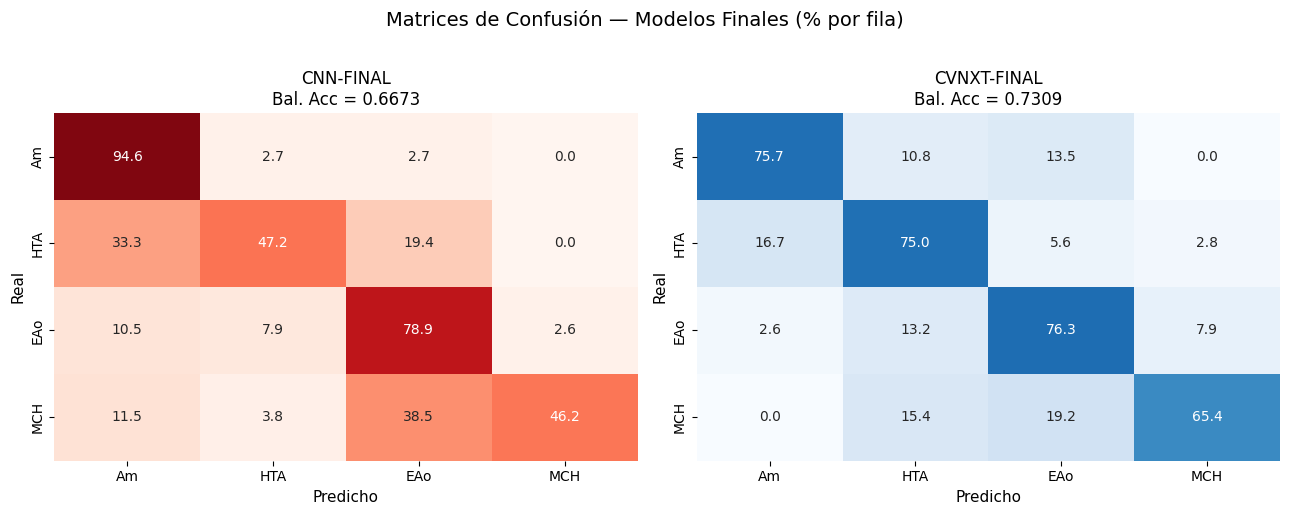

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, preds, name, ba, cmap in zip(
    axes,
    [cnn_preds,   cvnxt_preds],
    ['CNN-FINAL', 'CVNXT-FINAL'],
    [ba_cnn,      ba_cvnxt],
    ['Reds',      'Blues'],
):
    cm_mat = confusion_matrix(y_true, preds, normalize='true') * 100
    sns.heatmap(cm_mat, annot=True, fmt='.1f', cmap=cmap,
                xticklabels=CLASSES, yticklabels=CLASSES,
                vmin=0, vmax=100, ax=ax, cbar=False)
    ax.set_xlabel('Predicho', fontsize=11)
    ax.set_ylabel('Real',     fontsize=11)
    ax.set_title(f'{name}\nBal. Acc = {ba:.4f}', fontsize=12)

plt.suptitle('Matrices de Confusión — Modelos Finales (% por fila)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---
### **Predicciones por Imagen**

Verde = predicción correcta | Rojo = predicción incorrecta | Rank: posición de la clase real cuando el modelo falla, con su probabilidad entre paréntesis.

In [6]:
def rank_label(rank, ok, p_real):
    if ok:
        return '✓'
    label = {2: '2ª op', 3: '3ª op', 4: '4ª op'}.get(rank, str(rank))
    return f'{label} ({p_real:.2f})'

df['cnn_rank_lbl']   = [rank_label(r, ok, p)
                         for r, ok, p in zip(df['cnn_rank'],   df['cnn_ok'],   df['cnn_p_real'])]
df['cvnxt_rank_lbl'] = [rank_label(r, ok, p)
                         for r, ok, p in zip(df['cvnxt_rank'], df['cvnxt_ok'], df['cvnxt_p_real'])]

DISPLAY_COLS = ['imagen', 'clase_real',
                'cnn_pred', 'cnn_conf', 'cnn_rank_lbl',
                'cvnxt_pred', 'cvnxt_conf', 'cvnxt_rank_lbl']
COL_NAMES    = {
    'imagen': 'Imagen', 'clase_real': 'Real',
    'cnn_pred': 'CNN', 'cnn_conf': 'Conf. CNN', 'cnn_rank_lbl': 'Rank CNN',
    'cvnxt_pred': 'CVNXT', 'cvnxt_conf': 'Conf. CVNXT', 'cvnxt_rank_lbl': 'Rank CVNXT',
}

df_show = df[DISPLAY_COLS].rename(columns=COL_NAMES).copy()

def style_main(s):
    def highlight(row):
        styles   = [''] * len(row)
        col_map  = {c: i for i, c in enumerate(df_show.columns)}
        cnn_ok   = df.loc[row.name, 'cnn_ok']
        cvnxt_ok = df.loc[row.name, 'cvnxt_ok']
        styles[col_map['CNN']]   = ('background-color:#c8f7c5;font-weight:bold' if cnn_ok
                                    else 'background-color:#f8d7da;font-weight:bold')
        styles[col_map['CVNXT']] = ('background-color:#c8f7c5;font-weight:bold' if cvnxt_ok
                                    else 'background-color:#f8d7da;font-weight:bold')
        return styles
    return s.apply(highlight, axis=1).format({'Conf. CNN': '{:.3f}', 'Conf. CVNXT': '{:.3f}'})

display(df_show.style.pipe(style_main).hide(axis='index'))

Imagen,Real,CNN,Conf. CNN,Rank CNN,CVNXT,Conf. CVNXT,Rank CVNXT
Am/Am_100.jpg,Am,Am,0.936,✓,Am,0.889,✓
Am/Am_22.jpg,Am,Am,0.487,✓,Am,0.953,✓
Am/Am_23.jpg,Am,Am,0.979,✓,Am,0.996,✓
Am/Am_25.jpg,Am,Am,0.977,✓,Am,0.983,✓
Am/Am_35.jpg,Am,Am,0.993,✓,Am,0.998,✓
Am/Am_36.jpg,Am,Am,0.989,✓,Am,0.976,✓
Am/Am_51.jpg,Am,Am,0.862,✓,EAo,0.445,3ª op (0.20)
Am/Am_53.jpg,Am,Am,0.901,✓,Am,0.818,✓
Am/Am_58.jpg,Am,Am,0.976,✓,Am,0.918,✓
Am/Am_64.jpg,Am,Am,0.990,✓,Am,0.970,✓


In [7]:
# ── Dos tablas filtradas ──────────────────────────────────────────────────────
df_ok  = df[df['categoria'] == 'ambos_bien'].reset_index(drop=True)
df_err = df[df['categoria'] != 'ambos_bien'].reset_index(drop=True)

DISP_COLS  = ['imagen', 'clase_real',
              'cnn_pred', 'cnn_conf', 'cnn_rank_lbl',
              'cvnxt_pred', 'cvnxt_conf', 'cvnxt_rank_lbl']
COL_NAMES_T = {
    'imagen': 'Imagen', 'clase_real': 'Real',
    'cnn_pred': 'CNN', 'cnn_conf': 'Conf. CNN', 'cnn_rank_lbl': 'Rank CNN',
    'cvnxt_pred': 'CVNXT', 'cvnxt_conf': 'Conf. CVNXT', 'cvnxt_rank_lbl': 'Rank CVNXT',
}

def make_style(df_show, ref_df):
    cols    = list(df_show.columns)
    i_cnn   = cols.index('CNN')
    i_cvnxt = cols.index('CVNXT')
    def highlight(row):
        styles   = [''] * len(row)
        cnn_ok   = ref_df.loc[row.name, 'cnn_ok']
        cvnxt_ok = ref_df.loc[row.name, 'cvnxt_ok']
        styles[i_cnn]   = ('background-color:#c8f7c5;font-weight:bold' if cnn_ok
                            else 'background-color:#f8d7da;font-weight:bold')
        styles[i_cvnxt] = ('background-color:#c8f7c5;font-weight:bold' if cvnxt_ok
                            else 'background-color:#f8d7da;font-weight:bold')
        return styles
    return (df_show.style
            .apply(highlight, axis=1)
            .format({'Conf. CNN': '{:.3f}', 'Conf. CVNXT': '{:.3f}'}))

print(f'── Ambos correctos: {len(df_ok)} imágenes ──')
display(make_style(df_ok[DISP_COLS].rename(columns=COL_NAMES_T), df_ok).hide(axis='index'))

print(f'\n── Con al menos un error: {len(df_err)} imágenes ──')
display(make_style(df_err[DISP_COLS].rename(columns=COL_NAMES_T), df_err).hide(axis='index'))

── Ambos correctos: 80 imágenes ──


Imagen,Real,CNN,Conf. CNN,Rank CNN,CVNXT,Conf. CVNXT,Rank CVNXT
Am/Am_100.jpg,Am,Am,0.936,✓,Am,0.889,✓
Am/Am_22.jpg,Am,Am,0.487,✓,Am,0.953,✓
Am/Am_23.jpg,Am,Am,0.979,✓,Am,0.996,✓
Am/Am_25.jpg,Am,Am,0.977,✓,Am,0.983,✓
Am/Am_35.jpg,Am,Am,0.993,✓,Am,0.998,✓
Am/Am_36.jpg,Am,Am,0.989,✓,Am,0.976,✓
Am/Am_53.jpg,Am,Am,0.901,✓,Am,0.818,✓
Am/Am_58.jpg,Am,Am,0.976,✓,Am,0.918,✓
Am/Am_64.jpg,Am,Am,0.990,✓,Am,0.970,✓
Am/Am_66.jpg,Am,Am,0.988,✓,Am,0.968,✓



── Con al menos un error: 57 imágenes ──


Imagen,Real,CNN,Conf. CNN,Rank CNN,CVNXT,Conf. CVNXT,Rank CVNXT
Am/Am_51.jpg,Am,Am,0.862,✓,EAo,0.445,3ª op (0.20)
Am/Am_94.jpg,Am,Am,0.967,✓,HTA,0.646,2ª op (0.30)
Am/Am_170.jpg,Am,Am,0.353,✓,HTA,0.545,2ª op (0.38)
Am/Am_161.jpg,Am,Am,0.941,✓,EAo,0.479,2ª op (0.24)
Am/Am_165.jpg,Am,EAo,0.406,3ª op (0.26),EAo,0.802,3ª op (0.04)
Am/Am_103.jpg,Am,Am,0.560,✓,HTA,0.839,2ª op (0.13)
Am/Am_101.jpg,Am,Am,0.864,✓,EAo,0.447,3ª op (0.21)
Am/Am_157.jpg,Am,HTA,0.329,2ª op (0.32),HTA,0.659,3ª op (0.10)
Am/Am_159.jpg,Am,Am,0.883,✓,EAo,0.914,4ª op (0.01)
HTA/HTA_25.jpg,HTA,HTA,0.478,✓,Am,0.750,2ª op (0.25)


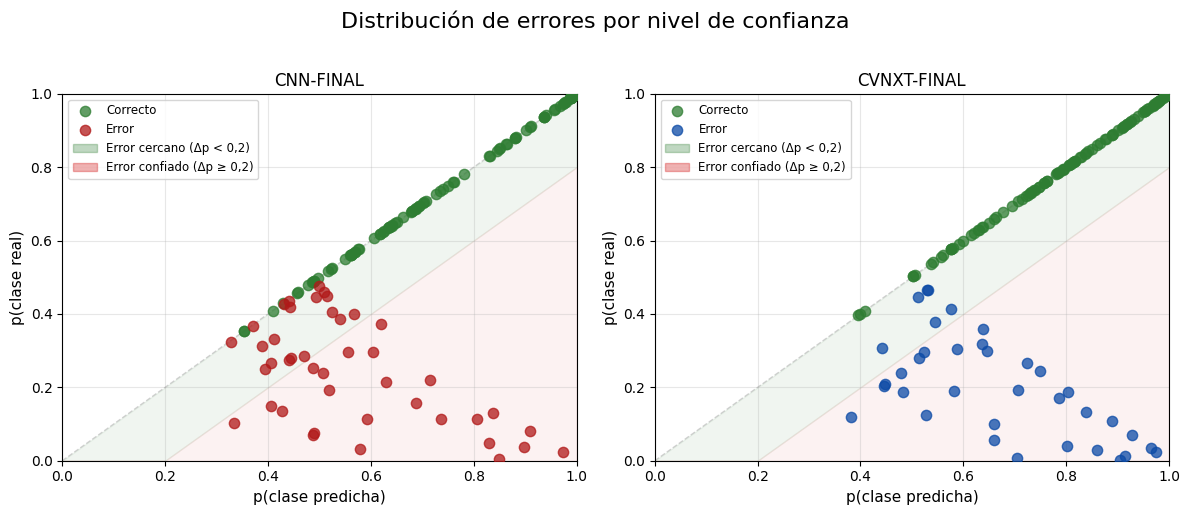

In [8]:
import matplotlib.patches as mpatches

# ── Scatter: confianza de predicción vs probabilidad de clase real ─────────────
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5))

x_bg   = np.linspace(0, 1, 200)
umbral = 0.2

for ax, conf_col, p_real_col, ok_col, err_color, title in [
    (ax0, 'cnn_conf',   'cnn_p_real',   'cnn_ok',   '#B11919', 'CNN-FINAL'),
    (ax1, 'cvnxt_conf', 'cvnxt_p_real', 'cvnxt_ok', '#0C4AA6', 'CVNXT-FINAL'),
]:
    ok = df[ok_col].values
    x  = df[conf_col].values
    y  = df[p_real_col].values

    ax.fill_between(x_bg,
                    np.clip(x_bg - umbral, 0, 1),
                    x_bg,
                    color='#2e7d32', alpha=0.07, zorder=0)
    ax.fill_between(x_bg,
                    np.zeros_like(x_bg),
                    np.clip(x_bg - umbral, 0, 1),
                    color='#cc0000', alpha=0.05, zorder=0)

    ax.scatter(x[ok],  y[ok],  color='#2e7d32', alpha=0.75, s=55, label='Correcto', zorder=3)
    ax.scatter(x[~ok], y[~ok], color=err_color,  alpha=0.75, s=55, label='Error',    zorder=3)
    ax.plot([0, 1], [0, 1], '--', color='gray', alpha=0.35, linewidth=1)
    ax.set_xlabel('p(clase predicha)', fontsize=11)
    ax.set_ylabel('p(clase real)',     fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)

    handles, labels = ax.get_legend_handles_labels()
    handles += [
        mpatches.Patch(color='#2e7d32', alpha=0.3, label='Error cercano (Δp < 0,2)'),
        mpatches.Patch(color='#cc0000', alpha=0.3, label='Error confiado (Δp ≥ 0,2)'),
    ]
    ax.legend(handles=handles, fontsize=8.5, loc='upper left')

plt.suptitle('Distribución de errores por nivel de confianza', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

Se consideran errores cercanos aquellos con una diferencia inferior a 0,20 entre p(predicha) y p(real), adoptando un criterio más conservador que el umbral de azar (0,25) para reflejar únicamente los casos de mayor ambigüedad

---
### **Distribución de Casos**

Para cada imagen del test se clasifica si ambos modelos aciertan, solo uno acierta, o ninguno. Cuantas más imágenes caigan en *Solo CNN* o *Solo CVNXT*, más potencial tiene el ensamble de recuperar casos que ningún modelo individual resuelve solo.

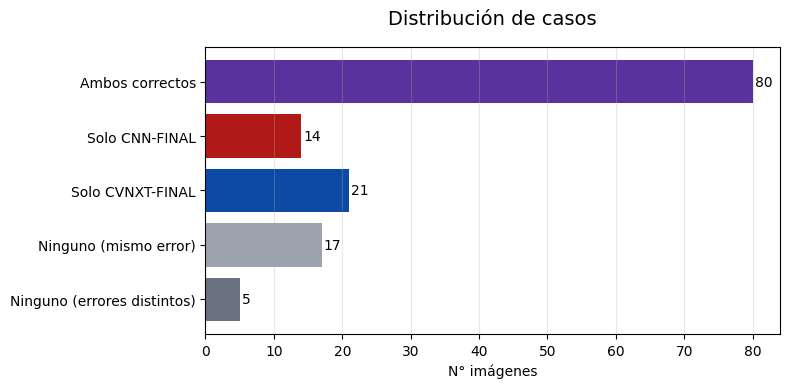

In [8]:
n = len(df)
cats = df['categoria'].value_counts()
n_ambos_bien = cats.get('ambos_bien', 0)
n_solo_cnn   = cats.get('solo_cnn',   0)
n_solo_cvnxt = cats.get('solo_cvnxt', 0)
n_ambos_mal  = cats.get('ambos_mal',  0)

df_mal       = df[df['categoria'] == 'ambos_mal']
mal_acuerdo  = (df_mal['cnn_pred'] == df_mal['cvnxt_pred']).sum()
mal_distinto = len(df_mal) - mal_acuerdo


COLOR_BIEN  = "#59329D"
COLOR_CNN   = '#B11919'
COLOR_CVNXT = '#0C4AA6'
COLOR_MAL   = '#9CA3AF'

fig, ax1 = plt.subplots(figsize=(8, 4))

# ── Barras ─────────────────────────────────────────────────────────────────────
labels = ['Ambos correctos', 'Solo CNN-FINAL', 'Solo CVNXT-FINAL',
          'Ninguno (mismo error)', 'Ninguno (errores distintos)']
values = [n_ambos_bien, n_solo_cnn, n_solo_cvnxt, mal_acuerdo, mal_distinto]
colors = [COLOR_BIEN, COLOR_CNN, COLOR_CVNXT, COLOR_MAL, '#6B7280']
ax1.barh(labels[::-1], values[::-1], color=colors[::-1])
for i, v in enumerate(values[::-1]):
    ax1.text(v + 0.3, i, str(v), va='center')
ax1.set_xlabel('N° imágenes')
ax1.set_title('Distribución de casos', fontsize=14, y=1.05)
ax1.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

---
## **RESULTADOS DEL ENSAMBLE**

Promedio ponderado de las probabilidades softmax: 40% CNN-FINAL + 60% CVNXT-FINAL.

Balanced Accuracy,Accuracy,Precision,Recall,F1-macro,F1-Am,F1-HTA,F1-EAo,F1-MCH
0.7809,0.7883,0.8010,0.7809,0.7869,0.8462,0.7397,0.7792,0.7826


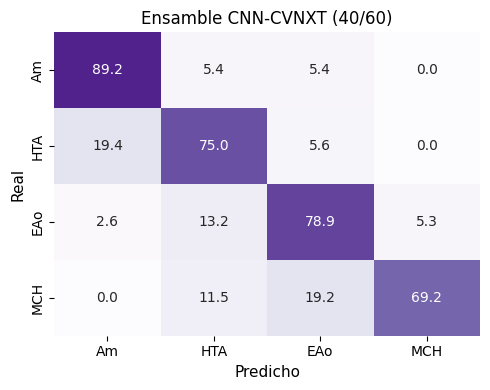

In [11]:
ens_probs = 0.4 * cnn_probs + 0.6 * cvnxt_probs
ens_preds = np.argmax(ens_probs, axis=1)
ba_ens    = balanced_accuracy_score(y_true, ens_preds)
acc_ens   = (ens_preds == y_true).mean()

report_ens = classification_report(y_true, ens_preds, target_names=CLASSES,
                                   output_dict=True, zero_division=0)

row_ens = {
    'Balanced Accuracy': round(ba_ens, 4),
    'Accuracy':          round(acc_ens, 4),
    'Precision':         round(float(np.mean([report_ens[c]['precision'] for c in CLASSES])), 4),
    'Recall':            round(float(np.mean([report_ens[c]['recall']    for c in CLASSES])), 4),
    'F1-macro':          round(report_ens['macro avg']['f1-score'], 4),
    'F1-Am':             round(report_ens['Am']['f1-score'],  4),
    'F1-HTA':            round(report_ens['HTA']['f1-score'], 4),
    'F1-EAo':            round(report_ens['EAo']['f1-score'], 4),
    'F1-MCH':            round(report_ens['MCH']['f1-score'], 4),
}

df_final_ens = pd.DataFrame([row_ens])
fmt_ens = {c: '{:.4f}' for c in df_final_ens.columns}
display(df_final_ens.style.format(fmt_ens).hide(axis='index'))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_true, ens_preds, normalize='true') * 100,
            annot=True, fmt='.1f', cmap='Purples',
            xticklabels=CLASSES, yticklabels=CLASSES,
            vmin=0, vmax=100, ax=ax, cbar=False)
ax.set_xlabel('Predicho', fontsize=11)
ax.set_ylabel('Real',     fontsize=11)
ax.set_title(f'Ensamble CNN-CVNXT (40/60)', fontsize=12)
plt.tight_layout()
plt.show()

### **Comparación de Modelos**

Modelo,Balanced Accuracy,Accuracy,Precision,Recall,F1-macro,F1-Am,F1-HTA,F1-EAo,F1-MCH
CNN-FINAL,0.6673,0.6861,0.7422,0.6673,0.6671,0.7692,0.5862,0.6977,0.6154
CVNXT-FINAL,0.7309,0.7372,0.7480,0.7309,0.7365,0.7778,0.7105,0.7342,0.7234
Ensamble 40/60,0.7809,0.7883,0.8010,0.7809,0.7869,0.8462,0.7397,0.7792,0.7826


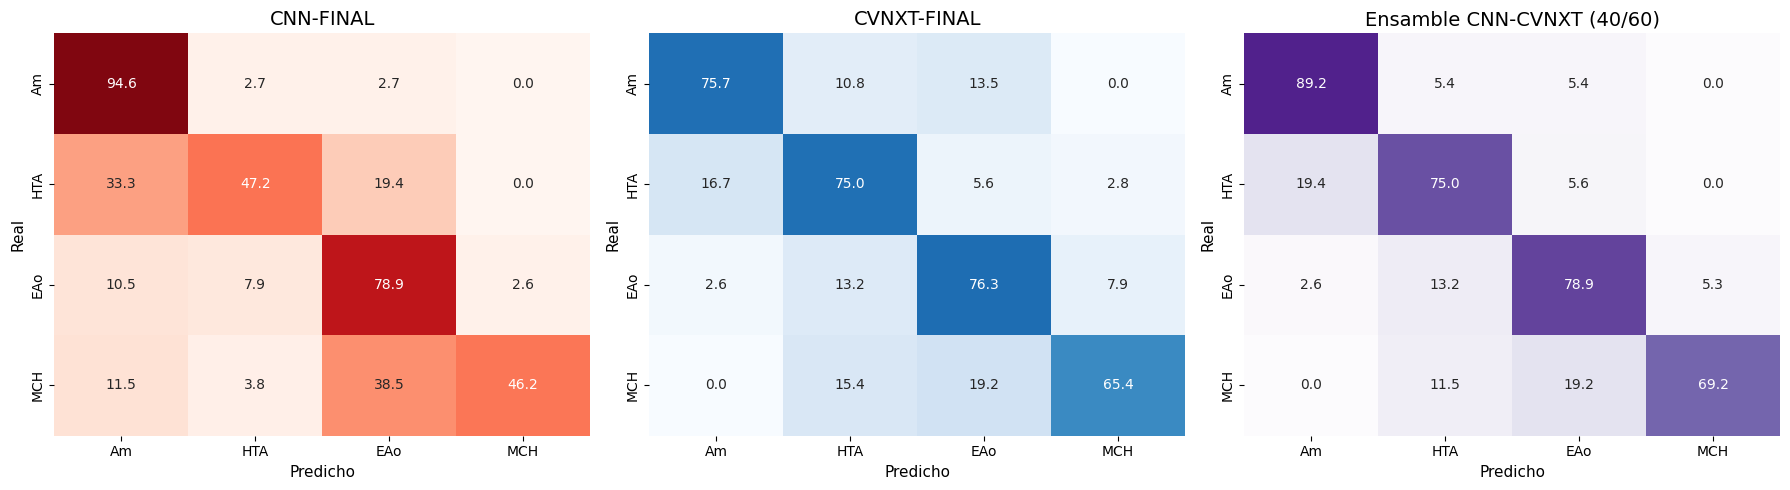

In [12]:
# ── Tabla resumen: 3 modelos ──────────────────────────────────────────────────
report_cnn   = classification_report(y_true, cnn_preds,   target_names=CLASSES, output_dict=True, zero_division=0)
report_cvnxt = classification_report(y_true, cvnxt_preds, target_names=CLASSES, output_dict=True, zero_division=0)

rows = []
for name, preds, report, ba in [
    ('CNN-FINAL',      cnn_preds,   report_cnn,   ba_cnn),
    ('CVNXT-FINAL',    cvnxt_preds, report_cvnxt, ba_cvnxt),
    ('Ensamble 40/60', ens_preds,   report_ens,   ba_ens),
]:
    rows.append({
        'Modelo':            name,
        'Balanced Accuracy': round(ba, 4),
        'Accuracy':          round((preds == y_true).mean(), 4),
        'Precision':         round(float(np.mean([report[c]['precision'] for c in CLASSES])), 4),
        'Recall':            round(float(np.mean([report[c]['recall']    for c in CLASSES])), 4),
        'F1-macro':          round(report['macro avg']['f1-score'], 4),
        'F1-Am':             round(report['Am']['f1-score'],  4),
        'F1-HTA':            round(report['HTA']['f1-score'], 4),
        'F1-EAo':            round(report['EAo']['f1-score'], 4),
        'F1-MCH':            round(report['MCH']['f1-score'], 4),
    })

df_summary = pd.DataFrame(rows)
mcols = [c for c in df_summary.columns if c != 'Modelo']
display(df_summary.style.format({c: '{:.4f}' for c in mcols}).hide(axis='index'))

# ── Subplot 3 matrices de confusión ───────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, preds, name, ba, cmap in zip(
    axes,
    [cnn_preds,   cvnxt_preds,   ens_preds],
    ['CNN-FINAL', 'CVNXT-FINAL', 'Ensamble CNN-CVNXT (40/60)'],
    [ba_cnn,      ba_cvnxt,      ba_ens],
    ['Reds',      'Blues',       'Purples'],
):
    cm_mat = confusion_matrix(y_true, preds, normalize='true') * 100
    sns.heatmap(cm_mat, annot=True, fmt='.1f', cmap=cmap,
                xticklabels=CLASSES, yticklabels=CLASSES,
                vmin=0, vmax=100, ax=ax, cbar=False)
    ax.set_xlabel('Predicho', fontsize=11)
    ax.set_ylabel('Real',     fontsize=11)
    ax.set_title(f'{name}', fontsize=14)

plt.tight_layout()
plt.show()